In [1]:
import torch
import torch.nn as nn

model = nn.Sequential(
    nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),
    nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
    nn.ReLU(),
    nn.Flatten(),
    nn.Linear(64 * 109 * 109, 10)
)

print(model)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): Flatten(start_dim=1, end_dim=-1)
  (6): Linear(in_features=760384, out_features=10, bias=True)
)


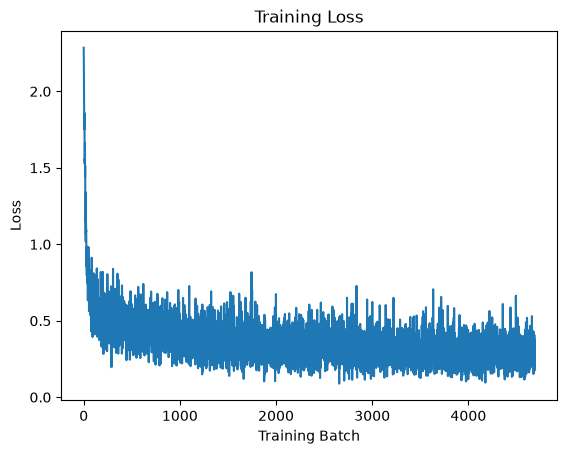

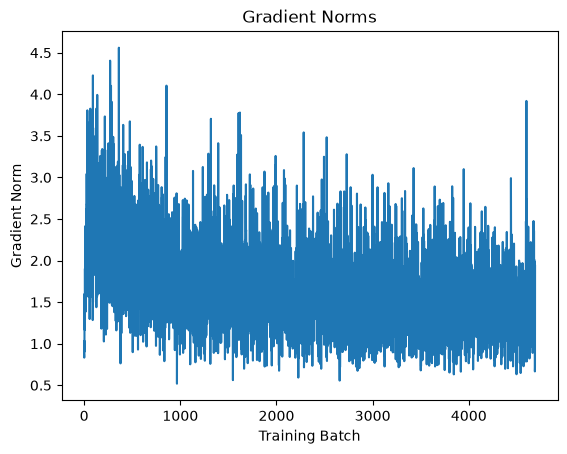

In [5]:
import torch
from torch import nn
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader
from torch import optim
import matplotlib.pyplot as plt


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5,],[0.5,])
])

training_data = datasets.FashionMNIST(
    root = "../../Data",
    train = True,
    download = True,
    transform = transform
)

train_dataloader = DataLoader(
    training_data,
    batch_size = 64,
    shuffle = True
)

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 20),
            nn.ReLU(),
            nn.Linear(20, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits


model = NeuralNetwork()

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)
epochs = 5
losses = []
gradient_norms = []

for epoch in range(epochs):

    for X, y in train_dataloader:
        predictions = model(X)
        loss = loss_fn(predictions, y)
        losses.append(loss.item())

        optimizer.zero_grad()
        loss.backward()

        gradient_norm = torch.norm(
            torch.cat([
                parameter.grad.flatten()
                for parameter in model.parameters()
                if parameter.grad is not None
            ])
        )

        gradient_norms.append(gradient_norm.item())

        optimizer.step()

torch.save(model.state_dict(), "model.pth")

plt.plot(losses)
plt.xlabel("Training Batch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

plt.plot(gradient_norms)
plt.xlabel("Training Batch")
plt.ylabel("Gradient Norm")
plt.title("Gradient Norms")
plt.show()


In [15]:
import torch

loss_fn = torch.nn.CrossEntropyLoss()

prediction = torch.tensor([[0.1, 3.0, 2.0]])
correct_answer = torch.tensor([0])

loss = loss_fn(prediction, correct_answer)

print(loss)

tensor(3.2527)


In [7]:
'''
import torch

x = torch.tensor(3.0, requires_grad = True)

y = x**2

print("y:", y)

y.backward()

print("gradient:", x.grad)

'''

'''
import torch

x = torch.tensor(3.0, requires_grad=True)

a = x * 2
b = a + 1
y = b ** 2

print(y)
print(y.grad_fn)

'''



import torch

x = torch.tensor(3.0, requires_grad=True)

a = x * 2
b = a + 1
y = b ** 2

y.backward()

print("x:", x)
print("a:", a)
print("b:", b)
print("y:", y)

print("x gradient:", x.grad)

x: tensor(3., requires_grad=True)
a: tensor(6., grad_fn=<MulBackward0>)
b: tensor(7., grad_fn=<AddBackward0>)
y: tensor(49., grad_fn=<PowBackward0>)
x gradient: tensor(28.)


In [8]:
import torch
from torch import nn
from torchvision import transforms
from torchvision import datasets
from torch.utils.data import DataLoader

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 20),
            nn.ReLU(),
            nn.Linear(20, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork()
model.load_state_dict(torch.load("model.pth"))

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5,],[0.5,])
])

test_data = datasets.FashionMNIST(
    root = "../../Data",
    train = False,
    transform = transform
)

test_dataloader = DataLoader(
    test_data,
    shuffle = False,
    batch_size = 1
)

model.eval()
with torch.no_grad():
    for X, y in test_dataloader:
        prediction = model(X)
        softmax = nn.Softmax(dim = 1)
        pred = softmax(prediction)
        pred = torch.argmax(pred)
        break

pred


tensor(9)

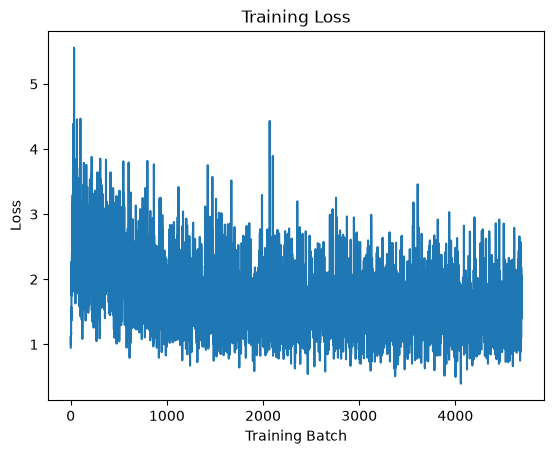

In [3]:
import torch
from torch import nn
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader
from torch import optim
import matplotlib.pyplot as plt

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5,],[0.5,])
])

training_data = datasets.FashionMNIST(
    root = "../../Data",
    train = True,
    transform = transform
)

train_dataloader = DataLoader(
    training_data,
    shuffle = True,
    batch_size = 64
)

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 20),
            nn.ReLU(),
            nn.Linear(20, 10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits


model = NeuralNetwork()

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)

epochs = 5
gradient_norms = []
losses = []

for epoch in range(epochs):

    for X, y in train_dataloader:
        prediction = model(X)
        loss = loss_fn(prediction, y)
        losses.append(loss.item())

        optimizer.zero_grad()
        loss.backward()

        gradient_norm = torch.norm(
            torch.cat([
                parameter.grad.flatten()
                for parameter in model.parameters()
                if parameter.grad is not None
            ])
        )

        gradient_norms.append(gradient_norm.item())

        optimizer.step()

torch.save(model.state_dict(), "model.pth")

plt.plot(gradient_norms)
plt.xlabel("Training Batch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()


In [4]:
import torch
from torch import nn
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 20),
            nn.ReLU(),
            nn.Linear(20,10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork()

model.load_state_dict(torch.load("model.pth"))



test_data = datasets.FashionMNIST(
    root = "../../Data",
    train = False,
    download = True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])
)

test_dataloader = DataLoader(
    test_data,
    batch_size = 1,
    shuffle = False
)

model.eval()
with torch.no_grad():
    for X, y in test_dataloader:
        prediction = model(X)
        softmax = nn.Softmax(dim = 1)
        pred = softmax(prediction)
        pred = torch.argmax(pred)
        break

print(prediction)
print(pred)



tensor([[ -5.9303, -12.0653, -10.2398,  -8.0298,  -7.9406,   4.0133,  -6.1309,
           2.6529,  -3.8206,   5.4974]])
tensor(9)


In [8]:
import torch
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import DataLoader
from torch import nn
from torch import optim

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

training_data = datasets.FashionMNIST(
    root = "../../Data",
    train = True,
    download = True,
    transform = transform
)

train_dataloader = DataLoader(
    training_data,
    batch_size = 64,
    shuffle = True
)


class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 20),
            nn.ReLU(),
            nn.Linear(20,10)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork()


loss_fn = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr= 0.001)

epochs = 5

for epoch in range(epochs):

    for X, y in train_dataloader:
        prediction = model(X)
        loss = loss_fn(prediction, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

torch.save(model.state_dict(), "model.pth")


In [11]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

model = NeuralNetwork()

model.load_state_dict(torch.load("model.pth"))

model.eval()
with torch.no_grad():
    prediction = model(X)

RuntimeError: Expected all tensors to be on the same device, but got mat1 is on cuda:0, different from other tensors on cpu (when checking argument in method wrapper_CUDA_addmm)

In [8]:
import torch

x = torch.tensor(3.0, requires_grad=True)

y = x**2

print("x:", x)
print("y:", y)

y.backward()

print("gradient:", x.grad)


x: tensor(3., requires_grad=True)
y: tensor(9., grad_fn=<PowBackward0>)
gradient: tensor(6.)


In [52]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

input_image = torch.rand(3, 28, 28)
flatten = nn.Flatten()
flat_image = flatten(input_image)

layer1 = nn.Linear(in_features = 28*28, out_features = 10)
hidden1 = layer1(flat_image)
hidden1.size()

print(f"Before ReLU: {hidden1}\n\n")
hidden1 = nn.ReLU()(hidden1)
print(f"After ReLU: {hidden1}")


seq_modules = nn.Sequential(
    flatten,
    layer1,
    nn.ReLU(),
    nn.Linear(10, 10)
)

input_image = torch.rand(3, 28, 28)
logits = seq_modules(input_image)

softmax = nn.Softmax(dim=1)
pred_proba = softmax(logits)
pred_proba.sum()

Before ReLU: tensor([[ 0.3825, -0.2550, -0.1805,  0.8555,  0.5136,  0.1212, -0.4249,  0.1935,
         -0.2579, -0.6060],
        [ 0.7115, -0.6128, -0.1703,  0.6524,  0.4425, -0.3672, -0.3927,  0.2323,
         -0.0860, -0.7200],
        [ 0.9223, -0.1532, -0.1269,  0.9154,  0.3260, -0.1969, -0.5949, -0.1137,
         -0.1895, -0.6754]], grad_fn=<AddmmBackward0>)


After ReLU: tensor([[0.3825, 0.0000, 0.0000, 0.8555, 0.5136, 0.1212, 0.0000, 0.1935, 0.0000,
         0.0000],
        [0.7115, 0.0000, 0.0000, 0.6524, 0.4425, 0.0000, 0.0000, 0.2323, 0.0000,
         0.0000],
        [0.9223, 0.0000, 0.0000, 0.9154, 0.3260, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000]], grad_fn=<ReluBackward0>)


tensor(3., grad_fn=<SumBackward0>)

In [ ]:
import os
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")


class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 10,)
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
# print(model)

X = torch.rand(1, 1, 28, 28, device = device)
logits = model(X)
pred_proba = nn.Softmax(dim=1)(logits)
y_pred = pred_proba.argmax(1)
# print(f"Predicted class is {y_pred}")


print(f"Model structure: {model}\n\n")

for name, param in model.named_parameters():
    print(f"Layer : {name} | Size : {param.size()} | Values : {param[:2]}\n")


torch.save(model.state_dict(), "model.pth")




Using cuda device
Model structure: NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=10, bias=True)
  )
)


Layer : linear_relu_stack.0.weight | Size : torch.Size([512, 784]) | Values : tensor([[ 0.0029, -0.0018, -0.0104,  ...,  0.0179, -0.0178, -0.0298],
        [-0.0136,  0.0198, -0.0117,  ..., -0.0059, -0.0323, -0.0306]],
       device='cuda:0', grad_fn=<SliceBackward0>)

Layer : linear_relu_stack.0.bias | Size : torch.Size([512]) | Values : tensor([0.0203, 0.0120], device='cuda:0', grad_fn=<SliceBackward0>)

Layer : linear_relu_stack.2.weight | Size : torch.Size([10, 512]) | Values : tensor([[-0.0425,  0.0421, -0.0040,  ..., -0.0418,  0.0318, -0.0349],
        [ 0.0415,  0.0031,  0.0398,  ...,  0.0081, -0.0210,  0.0153]],
       device='cuda:0', grad_fn=<SliceBackward0>)

Layer : linear_relu_stack.2.bias | Size : t

RuntimeError: Expected all tensors to be on the same device, but got mat1 is on cuda:0, different from other tensors on cpu (when checking argument in method wrapper_CUDA_addmm)

In [4]:
import torch
from torchvision import datasets
from torchvision import transforms

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5), (0.5))
])

training_data = datasets.FashionMNIST(
    root="../../data",
    train=True,
    download=True,
    transform = transform
)

from torch.utils.data import DataLoader
train_dataloader = DataLoader(
    training_data,
    batch_size = 64,
    shuffle = True
)




In [ ]:
import numpy as np
import torch

n1 = np.array([[1.0 ,2.0 ,3.0 ],
               [4.0 ,5.0 ,6.0 ]])
n1

t1 = torch.from_numpy(n1)
t1

t2 = t1 @ t1.T
print(t2)

t3 = t1.matmul(t1.T)
print(t3)

t4 = torch.rand_like(t2)

torch.matmul(t1, t1.T, out=t4)
print(t4)

agg = t4.sum()
print(agg)

agg_item = agg.item()
print(type(agg_item))


class MyDataset(Dataset):

    def __init__(self, data, labels):
        self.data = data
        self.labels = labels

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        return self.data[index], self.labels[index]

tensor([[14., 32.],
        [32., 77.]], dtype=torch.float64)
tensor([[14., 32.],
        [32., 77.]], dtype=torch.float64)
tensor([[14., 32.],
        [32., 77.]], dtype=torch.float64)
tensor(155., dtype=torch.float64)
<class 'float'>


In [ ]:
import numpy as np
import torch
tensor = torch.ones(4, 4)
print(f"First row: {tensor[0]}")
print(f"First column: {tensor[:, 0]}")
print(f"Last column: {tensor[..., -1]}")
tensor[:,1] = 0
print(tensor)
# We move our tensor to the current accelerator if available
if torch.accelerator.is_available():
    tensor = tensor.to(torch.accelerator.current_accelerator())

t1 = torch.cat([tensor, tensor, tensor])
print("t1 = \n",t1)


First row: tensor([1., 1., 1., 1.])
First column: tensor([1., 1., 1., 1.])
Last column: tensor([1., 1., 1., 1.])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
t1 = 
 tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]], device='cuda:0')


In [19]:
import numpy as np
import torch

# from data
data = [[1, 2],[3,4]]
x_data = torch.tensor(data)

# from numpy array
np_array = np.array(data)
x_np = torch.from_numpy(np_array)

# from another tensor
x_from_tensor = torch.ones_like(x_data)
print(x_from_tensor)

x_rand = torch.rand_like(x_data, dtype= torch.float64)
print(x_rand.device)

tensor([[1, 1],
        [1, 1]])
cpu
